In [1]:
# Standard Python utilities
import os
import csv
import json
import math
from pathlib import Path

In [2]:
# Arrays, images, plots and notebook display
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from IPython.display import display, Markdown

In [3]:
# Pretrained face detection and embedding models
import torch
from facenet_pytorch import MTCNN, InceptionResnetV1

In [4]:
# Clustering, evaluation and visualization
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

In [5]:
SEED = 42
K = 5
IMAGES_PER_PERSON = 20
EXTRA_PER_PERSON = 10
dataset_path = Path(os.environ.get("FACE_DATASET_DIR", "./lfw_funneled"))
save_dir = Path("./results")
save_dir.mkdir(exist_ok=True)
device = torch.device("cpu")

if not dataset_path.is_dir():
    raise FileNotFoundError(f"Dataset folder not found: {dataset_path.resolve()}")
print("Dataset:", dataset_path.resolve())
print("Outputs:", save_dir.resolve())

Dataset: C:\Users\UNI-TECH\Desktop\Image_grouper_project\lfw_funneled
Outputs: C:\Users\UNI-TECH\Desktop\Image_grouper_project\results


# 1. Select development images and preview the dataset

In [6]:
# Notebook ke saath maujood dataset folder

if not dataset_path.is_dir():
    raise FileNotFoundError(
        f"lfw_funneled folder nahi mila.\n"
        f"Notebook location: {Path.cwd()}"
    )

# Woh people select karein jinki kam az kam 20 photos hain
people = sorted(
    folder
    for folder in dataset_path.iterdir()
    if folder.is_dir()
    and len(list(folder.glob("*.jpg"))) >= 20
)

if len(people) < 5:
    raise ValueError(
        "Dataset mein 5 people ki required photos nahi milin."
    )

# Pehle experiment ke liye 5 people
selected_people = people[:K]

image_paths = []
true_labels = []

for person in selected_people:
    photos = sorted(person.glob("*.jpg"))[:IMAGES_PER_PERSON]

    image_paths.extend(photos)
    true_labels.extend([person.name] * len(photos))

print("Selected people:", len(selected_people))
print("Selected images:", len(image_paths))

# Har person ki ek sample photo dikhayein
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for ax, person in zip(axes, selected_people):
    photo = sorted(person.glob("*.jpg"))[0]

    with Image.open(photo) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(person.name.replace("_", " "), fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()


Selected people: 5
Selected images: 100


<Figure size 1500x400 with 5 Axes>

# 2. Reusable face extraction and clustering functions
Missing faces are recorded. Corrupt files raise an error rather than silently disappearing.

In [7]:
def make_detector(selection_method):
    """Create a detector using one consistent face-selection rule."""
    return MTCNN(image_size=160, margin=20, keep_all=False,
                 selection_method=selection_method, device=device)


def extract_embeddings(paths, labels, detector, model):
    """Return vectors and matching paths/labels; record no-face images."""
    vectors, kept_paths, kept_labels, skipped_paths = [], [], [], []
    with torch.inference_mode():
        for path, label in tqdm(zip(paths, labels), total=len(paths),
                                desc="Face embeddings"):
            with Image.open(path) as image:
                face = detector(image.convert("RGB"))
            if face is None:
                skipped_paths.append(str(path))
                continue
            vector = model(face.unsqueeze(0).to(device)).cpu().numpy()[0]
            vectors.append(vector)
            kept_paths.append(str(path))
            kept_labels.append(label)
    if not vectors:
        raise ValueError("No valid faces detected.")
    return np.stack(vectors), kept_paths, kept_labels, skipped_paths


def fit_clusters(vectors, labels, n_clusters):
    """Fit without identity labels; use identities only to compute ARI."""
    features = normalize(vectors, norm="l2")
    if not 2 <= n_clusters < len(features):
        raise ValueError("K must be at least 2 and less than the face count.")
    estimator = KMeans(n_clusters=n_clusters, init="k-means++",
                       n_init=20, random_state=SEED)
    predictions = estimator.fit_predict(features)
    if len(np.unique(predictions)) != n_clusters:
        raise ValueError("Fewer distinct clusters than requested.")
    scores = {"ari": float(adjusted_rand_score(labels, predictions)),
              "silhouette": float(silhouette_score(features, predictions))}
    return features, estimator, predictions, scores


model = InceptionResnetV1(pretrained="vggface2").eval().to(device)
print("Pretrained embedding model ready.")


  0%|          | 0.00/107M [00:00<?, ?B/s]

Pretrained embedding model ready.


# 3. Baseline experiment
Baseline metrics below are calculated, not hard-coded.

In [8]:
baseline_detector = make_detector("largest")
baseline_vectors, baseline_paths, baseline_labels, baseline_skipped = extract_embeddings(
    image_paths, true_labels, baseline_detector, model)
_, baseline_model, baseline_predictions, baseline_scores = fit_clusters(
    baseline_vectors, baseline_labels, K)
baseline_ari = baseline_scores["ari"]
baseline_silhouette = baseline_scores["silhouette"]
print("Baseline metrics:", baseline_scores)
print("Baseline skipped:", len(baseline_skipped))


Face embeddings: 100%|██████████| 100/100 [00:20<00:00,  4.95it/s]


Baseline metrics: {'ari': 0.9746088740702744, 'silhouette': 0.45865345001220703}
Baseline skipped: 0


# 4. Face-selection error analysis
Compare both rules on the development image that previously received a background crop. No image is removed to improve the score.

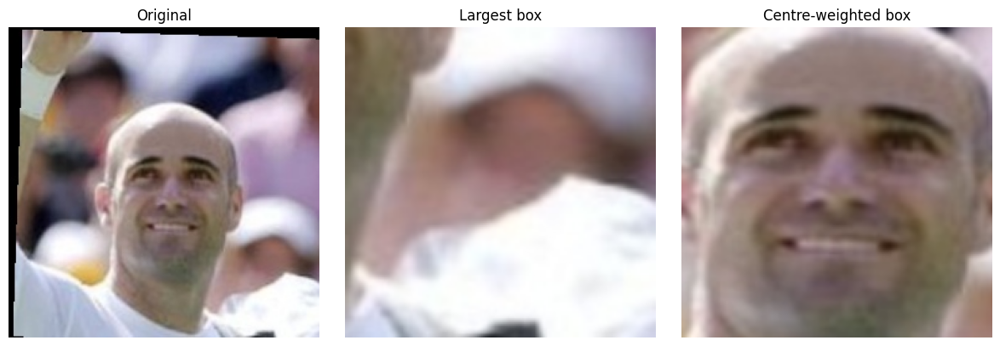

In [10]:
mtcnn = make_detector("center_weighted_size")
example = dataset_path / "Andre_Agassi" / "Andre_Agassi_0018.jpg"
if example.is_file():
    with Image.open(example) as image:
        original = image.convert("RGB")
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(original)
    axes[0].set_title("Original")
    for ax, detector, title in zip(axes[1:], [baseline_detector, mtcnn],
                                     ["Largest box", "Centre-weighted box"]):
        crop = detector(original)
        if crop is not None:
            pixels = crop.cpu().permute(1, 2, 0).numpy()
            ax.imshow(((pixels * 128 + 127.5) / 255).clip(0, 1))
        ax.set_title(title)
    for ax in axes:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(save_dir / "face_selection_comparison.png", dpi=150)
    plt.show()


# 5. Revised experiment
Apply the same revised rule to every image and retain a fixed K=5.

In [11]:
embeddings, valid_paths, valid_labels, skipped = extract_embeddings(
    image_paths, true_labels, mtcnn, model)
X, kmeans, cluster_labels, final_scores = fit_clusters(embeddings, valid_labels, K)
k = K
ari = final_scores["ari"]
silhouette = final_scores["silhouette"]
print("Embedding shape:", embeddings.shape)
print("Skipped images:", len(skipped))
for cluster_id in range(k):
    print(f"Cluster {cluster_id}: {np.sum(cluster_labels == cluster_id)} faces")
print(f"ARI: {baseline_ari:.4f} -> {ari:.4f}")
print(f"Silhouette: {baseline_silhouette:.4f} -> {silhouette:.4f}")


Face embeddings: 100%|██████████| 100/100 [00:16<00:00,  5.89it/s]


Embedding shape: (100, 512)
Skipped images: 0
Cluster 0: 20 faces
Cluster 1: 20 faces
Cluster 2: 20 faces
Cluster 3: 20 faces
Cluster 4: 20 faces
ARI: 0.9746 -> 1.0000
Silhouette: 0.4587 -> 0.4678


# 6. Save embeddings and metrics

In [12]:
save_dir = Path("./results")
save_dir.mkdir(exist_ok=True)

np.savez_compressed(
    save_dir / "face_clustering_results.npz",
    embeddings=embeddings,
    normalized_embeddings=X,
    image_paths=np.asarray(valid_paths, dtype=str),
    true_labels=np.asarray(valid_labels, dtype=str),
    cluster_labels=cluster_labels,
    cluster_centers=kmeans.cluster_centers_
)

metrics = {
    "processed_faces": len(valid_paths),
    "skipped_images": len(skipped),
    "number_of_clusters": k,
    "selection_method": mtcnn.selection_method,
    "baseline_ari": baseline_ari,
    "updated_ari": float(ari),
    "baseline_silhouette": baseline_silhouette,
    "updated_silhouette": float(silhouette)
}

with open(save_dir / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("Saved in:", save_dir.resolve())
print("Embeddings aur evaluation results save ho gaye.")


Saved in: C:\Users\UNI-TECH\Desktop\Image_grouper_project\results
Embeddings aur evaluation results save ho gaye.


# 7. PCA visualization
PCA is for display only. Clustering uses all 512 normalized features; overlap in this projection does not prove an error.

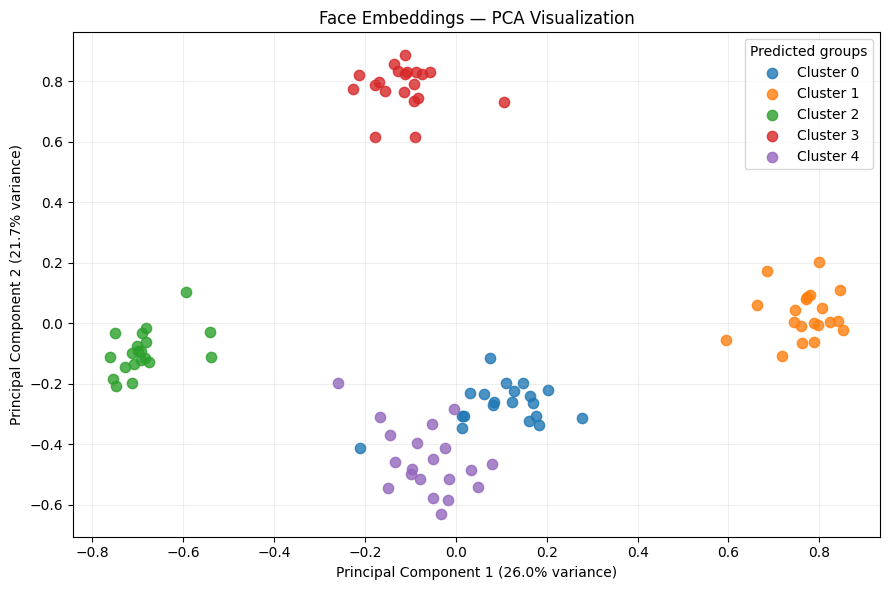

Variance captured in 2D: 47.7%
Plot saved: results\pca_clusters.png


In [13]:
# Sirf visualization ke liye 512 dimensions → 2
pca = PCA(n_components=2, random_state=42)
points_2d = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(9, 6))

for cluster_id in range(k):
    mask = cluster_labels == cluster_id

    ax.scatter(
        points_2d[mask, 0],
        points_2d[mask, 1],
        label=f"Cluster {cluster_id}",
        s=55,
        alpha=0.8
    )

variance = pca.explained_variance_ratio_

ax.set_xlabel(f"Principal Component 1 ({variance[0]:.1%} variance)")
ax.set_ylabel(f"Principal Component 2 ({variance[1]:.1%} variance)")
ax.set_title("Face Embeddings — PCA Visualization")
ax.legend(title="Predicted groups")
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    save_dir / "pca_clusters.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print(f"Variance captured in 2D: {variance.sum():.1%}")
print("Plot saved:", save_dir / "pca_clusters.png")


# 8. Compare K=2–10
Inertia decreases as K increases. Inspect the elbow and silhouette together. ARI is an external evaluation measure, not a training input.

K= 2 | Inertia=66.63 | Silhouette=0.2285 | ARI=0.3654
K= 3 | Inertia=50.68 | Silhouette=0.3073 | ARI=0.6056
K= 4 | Inertia=36.15 | Silhouette=0.3979 | ARI=0.7755
K= 5 | Inertia=24.54 | Silhouette=0.4678 | ARI=1.0000
K= 6 | Inertia=23.57 | Silhouette=0.4030 | ARI=0.9329
K= 7 | Inertia=23.08 | Silhouette=0.3278 | ARI=0.8714
K= 8 | Inertia=22.21 | Silhouette=0.2988 | ARI=0.8804
K= 9 | Inertia=21.66 | Silhouette=0.2638 | ARI=0.7634
K=10 | Inertia=21.23 | Silhouette=0.2818 | ARI=0.8020


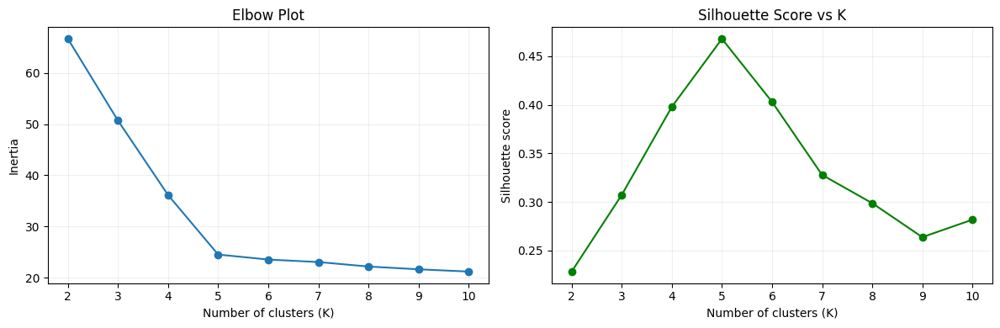


Highest silhouette among tested values: K=5 (0.4678)
Comparison CSV aur plots save ho gaye.


In [14]:
k_values = list(range(2, 11))
comparison = []

for candidate_k in k_values:
    # Separate model: final K=5 model overwrite nahi hoga
    candidate_model = KMeans(
        n_clusters=candidate_k,
        init="k-means++",
        n_init=20,
        random_state=42
    )

    candidate_labels = candidate_model.fit_predict(X)

    row = {
        "k": candidate_k,
        "inertia": float(candidate_model.inertia_),
        "silhouette": float(
            silhouette_score(X, candidate_labels)
        ),
        # Identities sirf evaluation ke liye
        "ari": float(
            adjusted_rand_score(valid_labels, candidate_labels)
        )
    }

    comparison.append(row)

    print(
        f"K={candidate_k:2d} | "
        f"Inertia={row['inertia']:.2f} | "
        f"Silhouette={row['silhouette']:.4f} | "
        f"ARI={row['ari']:.4f}"
    )

# Results table save karna
with open(
    save_dir / "k_comparison.csv",
    "w",
    newline="",
    encoding="utf-8"
) as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["k", "inertia", "silhouette", "ari"]
    )
    writer.writeheader()
    writer.writerows(comparison)

# Elbow aur silhouette plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    k_values,
    [r["inertia"] for r in comparison],
    marker="o"
)
axes[0].set_title("Elbow Plot")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    k_values,
    [r["silhouette"] for r in comparison],
    marker="o",
    color="green"
)
axes[1].set_title("Silhouette Score vs K")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette score")

for ax in axes:
    ax.set_xticks(k_values)
    ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    save_dir / "k_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

best = max(comparison, key=lambda r: r["silhouette"])

print(
    f"\nHighest silhouette among tested values: "
    f"K={best['k']} ({best['silhouette']:.4f})"
)
print("Comparison CSV aur plots save ho gaye.")


# 9. Additional-image validation
Use filenames 21–30 when available, disjoint from the first 20. Keep the original K-Means centres fixed. Map clusters to identities using development labels only. This checks known identities, not recognition of unseen people.

In [15]:
# Har selected person ki pehli 20 photos already use hui hain.
# Ab uske baad wali maximum 10 photos lena.
extra_paths = []
extra_true_labels = []

for person in selected_people:
    photos = sorted(person.glob("*.jpg"))[20:30]
    extra_paths.extend(photos)
    extra_true_labels.extend([person.name] * len(photos))

print("Available additional images:", len(extra_paths))

extra_embeddings = []
extra_valid_paths = []
extra_valid_labels = []
extra_skipped = []

with torch.inference_mode():
    for path, label in tqdm(
        zip(extra_paths, extra_true_labels),
        total=len(extra_paths),
        desc="Additional image embeddings"
    ):
        with Image.open(path) as img:
            face = mtcnn(img.convert("RGB"))

        if face is None:
            extra_skipped.append(str(path))
            continue

        vector = model(
            face.unsqueeze(0).to(device)
        ).cpu().numpy()[0]

        extra_embeddings.append(vector)
        extra_valid_paths.append(str(path))
        extra_valid_labels.append(label)

if not extra_embeddings:
    raise ValueError("Additional images mein valid faces nahi mile.")

extra_X = normalize(np.stack(extra_embeddings), norm="l2")

# Existing model se assign karna — fit dobara nahi karna
extra_predictions = kmeans.predict(extra_X)

# Original sample se cluster → person mapping freeze karna
cluster_to_person = {}

for cluster_id in range(k):
    members = [
        valid_labels[i]
        for i in range(len(valid_labels))
        if cluster_labels[i] == cluster_id
    ]
    names, counts = np.unique(members, return_counts=True)
    cluster_to_person[cluster_id] = names[counts.argmax()]

predicted_people = [
    cluster_to_person[int(c)] for c in extra_predictions
]

correct = sum(
    actual == predicted
    for actual, predicted in zip(
        extra_valid_labels, predicted_people
    )
)

assignment_accuracy = correct / len(extra_valid_labels)

print("\nProcessed additional faces:", len(extra_valid_labels))
print("Skipped:", len(extra_skipped))
print(
    f"Fixed-mapping identity assignment accuracy: "
    f"{assignment_accuracy:.2%}"
)

if len(set(extra_valid_labels)) > 1:
    extra_ari = adjusted_rand_score(
        extra_valid_labels, extra_predictions
    )
    print(f"Additional-image ARI: {extra_ari:.4f}")
else:
    extra_ari = None
    print("ARI report nahi kiya: sirf ek identity available hai.")

print("\nImages per person:")
for person in sorted(set(extra_valid_labels)):
    total = extra_valid_labels.count(person)
    print(person.replace("_", " "), ":", total)

validation_results = {
    "available_images": len(extra_paths),
    "processed_faces": len(extra_valid_labels),
    "skipped_images": len(extra_skipped),
    "fixed_mapping_assignment_accuracy": assignment_accuracy,
    "ari": extra_ari
}

with open(
    save_dir / "additional_validation.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(validation_results, f, indent=2)

np.savez_compressed(
    save_dir / "additional_validation.npz",
    normalized_embeddings=extra_X,
    image_paths=np.asarray(extra_valid_paths, dtype=str),
    true_labels=np.asarray(extra_valid_labels, dtype=str),
    predicted_clusters=extra_predictions,
    predicted_people=np.asarray(predicted_people, dtype=str)
)


Available additional images: 31


Additional image embeddings: 100%|██████████| 31/31 [00:05<00:00,  6.07it/s]


Processed additional faces: 31
Skipped: 0
Fixed-mapping identity assignment accuracy: 100.00%
Additional-image ARI: 1.0000

Images per person:
Alejandro Toledo : 10
Alvaro Uribe : 10
Amelie Mauresmo : 1
Andre Agassi : 10


# 10. Final identity/cluster heatmap

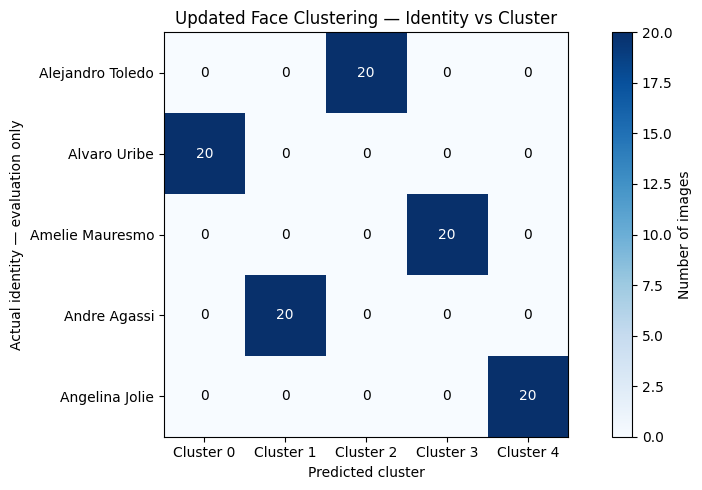

Updated heatmap saved.


In [16]:
person_names = sorted(set(valid_labels))
true_array = np.asarray(valid_labels)

counts = np.zeros((len(person_names), k), dtype=int)

for row, person in enumerate(person_names):
    for cluster_id in range(k):
        counts[row, cluster_id] = np.sum(
            (true_array == person)
            & (cluster_labels == cluster_id)
        )

fig, ax = plt.subplots(figsize=(9, 5))

heatmap = ax.imshow(counts, cmap="Blues")

ax.set_xticks(range(k))
ax.set_xticklabels([f"Cluster {i}" for i in range(k)])

ax.set_yticks(range(len(person_names)))
ax.set_yticklabels([
    name.replace("_", " ") for name in person_names
])

for row in range(counts.shape[0]):
    for col in range(counts.shape[1]):
        ax.text(
            col, row, str(counts[row, col]),
            ha="center",
            va="center",
            color=(
                "white"
                if counts[row, col] > counts.max() / 2
                else "black"
            )
        )

ax.set_xlabel("Predicted cluster")
ax.set_ylabel("Actual identity — evaluation only")
ax.set_title("Updated Face Clustering — Identity vs Cluster")

fig.colorbar(heatmap, ax=ax, label="Number of images")
fig.tight_layout()

fig.savefig(
    save_dir / "updated_identity_cluster_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("Updated heatmap saved.")


# 11. Full galleries
These show source photos, not the extracted crops. Identity titles come from dataset labels and are not names inferred by K-Means.

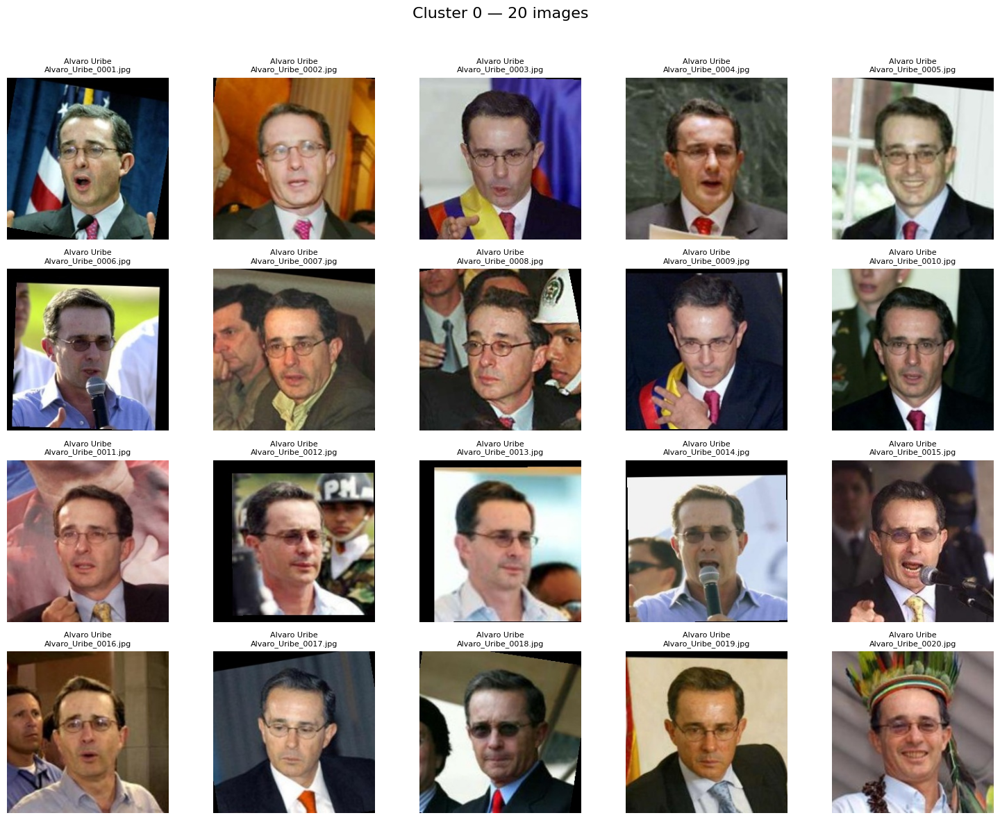

Saved: results\cluster_galleries\cluster_0.png


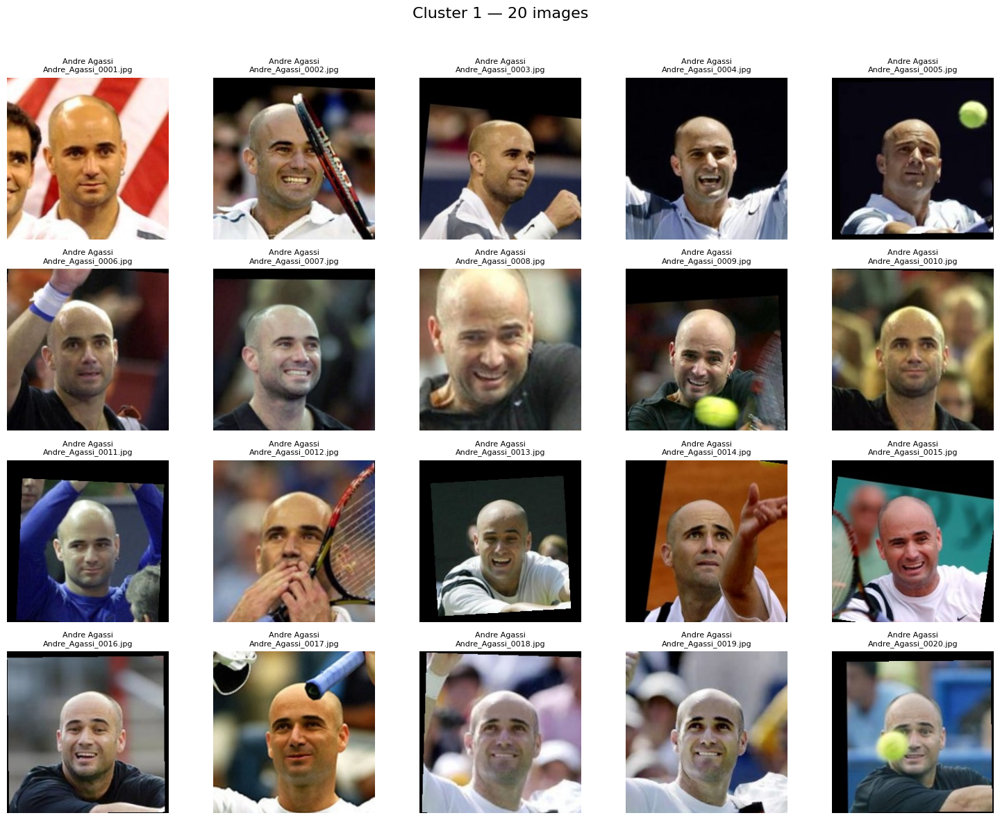

Saved: results\cluster_galleries\cluster_1.png


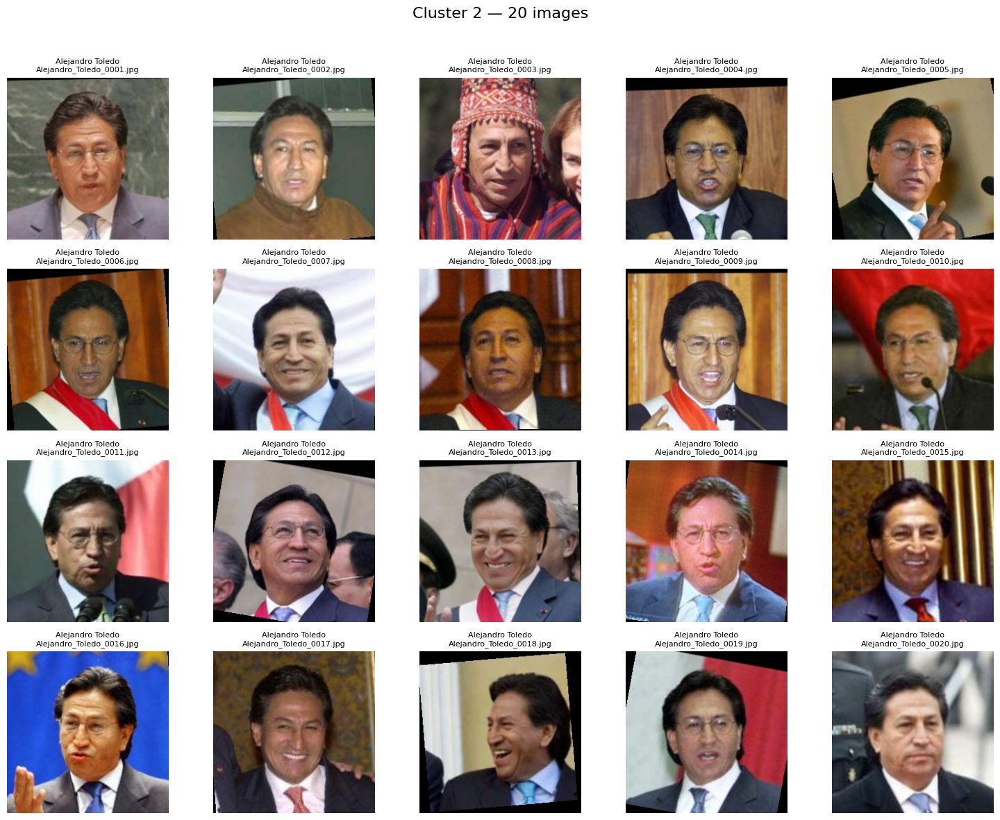

Saved: results\cluster_galleries\cluster_2.png


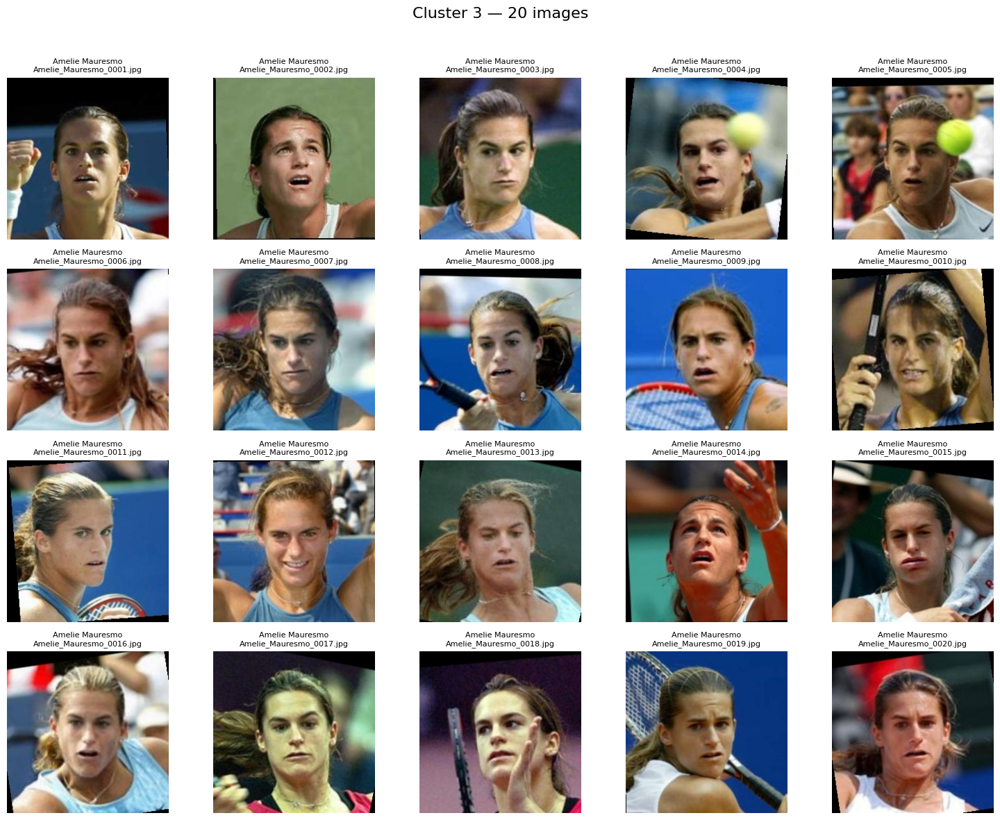

Saved: results\cluster_galleries\cluster_3.png


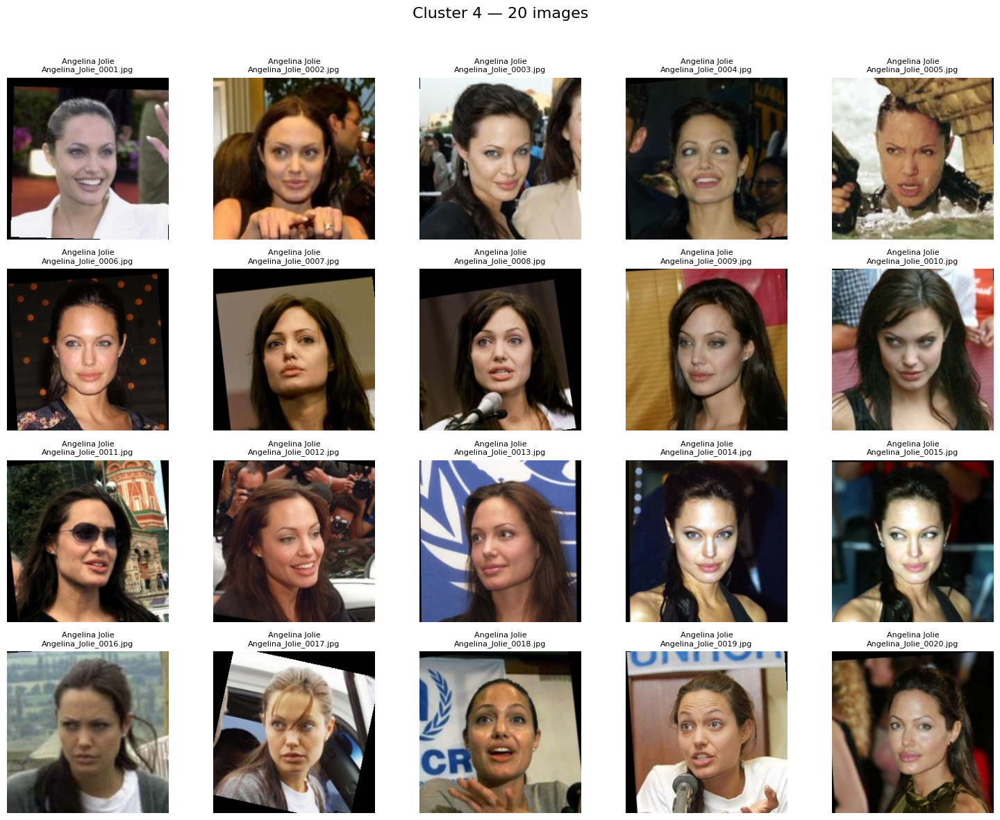

Saved: results\cluster_galleries\cluster_4.png


In [17]:
gallery_dir = save_dir / "cluster_galleries"
gallery_dir.mkdir(exist_ok=True)

for cluster_id in range(k):
    indices = np.where(cluster_labels == cluster_id)[0]

    columns = 5
    rows = math.ceil(len(indices) / columns)

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(15, rows * 3),
        squeeze=False
    )

    fig.suptitle(
        f"Cluster {cluster_id} — {len(indices)} images",
        fontsize=16
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, index in zip(axes.flat, indices):
        path = valid_paths[index]

        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))

        # Actual names evaluation ke liye dikhaye gaye hain
        name = valid_labels[index].replace("_", " ")
        filename = Path(path).name

        ax.set_title(
            f"{name}\n{filename}",
            fontsize=8
        )

    fig.tight_layout(rect=[0, 0, 1, 0.96])

    output_path = gallery_dir / f"cluster_{cluster_id}.png"

    fig.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", output_path)


# 12. Per-image exports and summary

In [18]:
# Har original image ka assigned cluster
with open(
    save_dir / "main_image_assignments.csv",
    "w", newline="", encoding="utf-8"
) as f:
    writer = csv.writer(f)
    writer.writerow(["image_path", "actual_identity", "cluster"])

    writer.writerows(
        zip(valid_paths, valid_labels, cluster_labels)
    )

# Additional images ke predictions
with open(
    save_dir / "additional_image_assignments.csv",
    "w", newline="", encoding="utf-8"
) as f:
    writer = csv.writer(f)
    writer.writerow([
        "image_path",
        "actual_identity",
        "predicted_cluster",
        "mapped_identity"
    ])

    writer.writerows(zip(
        extra_valid_paths,
        extra_valid_labels,
        extra_predictions,
        predicted_people
    ))

# Saved validation results se summary
with open(
    save_dir / "additional_validation.json",
    encoding="utf-8"
) as f:
    validation = json.load(f)

summary = f"""
### Final Experiment Results

| Experiment | Images | ARI | Silhouette |
|---|---:|---:|---:|
| Initial face selection | 100 | {baseline_ari:.4f} | {baseline_silhouette:.4f} |
| Updated face selection | {len(valid_paths)} | {ari:.4f} | {silhouette:.4f} |

**Additional-image validation**

- Processed images: {validation["processed_faces"]}
- Identities represented: {len(set(extra_valid_labels))}
- Fixed-mapping assignment accuracy: {validation["fixed_mapping_assignment_accuracy"]:.2%}
- ARI: {validation["ari"]:.4f}
- Skipped images: {validation["skipped_images"]}

**Method:** MTCNN face detection/cropping → pretrained
InceptionResnetV1 (VGGFace2) embeddings → L2 normalization →
K-Means clustering.

**Selected K:** 5. This value also had the highest silhouette
score among the tested values from 2 to 10.
"""

display(Markdown(summary))

(save_dir / "experiment_summary.md").write_text(
    summary,
    encoding="utf-8"
)

print("Summary aur dono assignment CSV files save ho gayi.")



### Final Experiment Results

| Experiment | Images | ARI | Silhouette |
|---|---:|---:|---:|
| Initial face selection | 100 | 0.9746 | 0.4587 |
| Updated face selection | 100 | 1.0000 | 0.4678 |

**Additional-image validation**

- Processed images: 31
- Identities represented: 4
- Fixed-mapping assignment accuracy: 100.00%
- ARI: 1.0000
- Skipped images: 0

**Method:** MTCNN face detection/cropping → pretrained
InceptionResnetV1 (VGGFace2) embeddings → L2 normalization →
K-Means clustering.

**Selected K:** 5. This value also had the highest silhouette
score among the tested values from 2 to 10.


Summary aur dono assignment CSV files save ho gayi.


In [19]:
import joblib

# Fitted clustering model
joblib.dump(kmeans, save_dir / "kmeans_model.joblib")

# FaceNet weights: offline reuse ke liye
torch.save(
    model.state_dict(),
    save_dir / "facenet_vggface2_weights.pth"
)

print("K-Means model aur FaceNet weights save ho gaye.")

K-Means model aur FaceNet weights save ho gaye.


In [20]:
# Saved K-Means load karke original predictions se compare karna
loaded_kmeans = joblib.load(save_dir / "kmeans_model.joblib")
loaded_predictions = loaded_kmeans.predict(X)

same_predictions = np.array_equal(
    cluster_labels,
    loaded_predictions
)

# Saved FaceNet weights check karna
saved_weights = torch.load(
    save_dir / "facenet_vggface2_weights.pth",
    map_location="cpu",
    weights_only=True
)

same_weights = (
    saved_weights.keys() == model.state_dict().keys()
    and all(
        torch.equal(saved_weights[name], value.cpu())
        for name, value in model.state_dict().items()
    )
)

print("K-Means predictions match:", same_predictions)
print("FaceNet weights match:", same_weights)

assert same_predictions, "Saved K-Means predictions mismatch."
assert same_weights, "Saved FaceNet weights mismatch."

print("Saved models verified successfully!")

K-Means predictions match: True
FaceNet weights match: True
Saved models verified successfully!
